Mounted at /content/drive
✅ Original image exported with identical file bytes.
Original dimensions: 1024 × 584
New model calls: 0
Saved: /content/drive/MyDrive/RPVC01/pilot/part07_reading_label_audit/runs/20261025T110616Z_d59c97d1_read10/read10_original.png


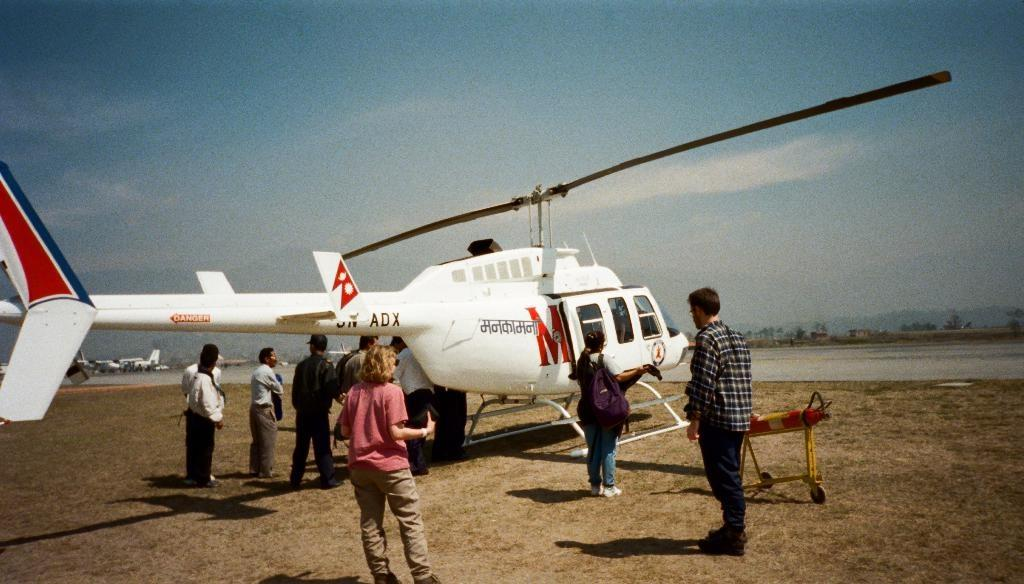

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
# CELL 1 — EXPORT ORIGINAL READING IMAGE FOR LABEL ADJUDICATION
# CPU only. No inference. Notebook 07 results remain unchanged.

import json
import hashlib
from pathlib import Path
from datetime import datetime, timezone

from PIL import Image
from IPython.display import display
from google.colab import drive, files

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/RPVC01/pilot")
RUN = ROOT / "part07_replication/runs/20261025T110616Z_d59c97d1"
AUDIT = (
    ROOT / "part07_reading_label_audit/runs" /
    "20261025T110616Z_d59c97d1_read10"
)
AUDIT.mkdir(parents=True, exist_ok=True)

frozen = json.loads((RUN / "data/frozen_inputs.json").read_text())
case = next(
    row for row in frozen["utility_cases"]
    if row["id"] == "read_10"
)

source = RUN / case["source_file"]
image_bytes = source.read_bytes()
source_sha = hashlib.sha256(image_bytes).hexdigest()

if source_sha != case["source_file_sha256"]:
    raise RuntimeError("Source image differs from the frozen record.")

destination = AUDIT / ("read10_original" + source.suffix.lower())
if destination.exists():
    if hashlib.sha256(destination.read_bytes()).hexdigest() != source_sha:
        raise RuntimeError("An existing audit image differs; nothing overwritten.")
else:
    temporary = destination.with_suffix(destination.suffix + ".partial")
    temporary.write_bytes(image_bytes)
    temporary.replace(destination)

with Image.open(source) as opened:
    image = opened.copy()
    dimensions = list(opened.size)

manifest = {
    "created_at": datetime.now(timezone.utc).isoformat(),
    "parent_run": RUN.name,
    "parent_freeze_id": frozen["freeze_id"],
    "case_id": "read_10",
    "source_file": str(source),
    "source_sha256": source_sha,
    "original_dimensions": dimensions,
    "export_file": str(destination),
    "purpose": "Original-pixel label adjudication only",
    "new_model_calls": 0,
    "parent_inputs_and_results_modified": False,
}

manifest_path = AUDIT / "export_manifest.json"
if not manifest_path.exists():
    manifest_path.write_text(
        json.dumps(manifest, indent=2), encoding="utf-8"
    )

print("✅ Original image exported with identical file bytes.")
print(f"Original dimensions: {dimensions[0]} × {dimensions[1]}")
print("New model calls: 0")
print("Saved:", destination)
display(image)
files.download(str(destination))

In [2]:
# CELL 2 — FINALIZE THE READING-LABEL AUDIT AND BACK UP
# CPU only. No model calls or changes to Notebook 07 results.

import json
import hashlib
import zipfile
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/RPVC01/pilot")
AUDIT = (
    ROOT / "part07_reading_label_audit/runs" /
    "20261025T110616Z_d59c97d1_read10"
)

manifest = json.loads((AUDIT / "export_manifest.json").read_text())
image_path = Path(manifest["export_file"])
image_sha = hashlib.sha256(image_path.read_bytes()).hexdigest()

if image_sha != (
    "61bf8e0ebbbab065195456b6ed1da84fb"
    "a6dfb7d8ca1478bfe0318cc514b9d07"
):
    raise RuntimeError("Image differs from the original inspected in chat.")

decision = {
    "review_date": "2026-10-26",
    "parent_run": manifest["parent_run"],
    "case_id": "read_10",
    "source_sha256": image_sha,
    "review_method": "Assistant visual inspection of original source pixels",
    "confirmed_visible_text": "ADX",
    "unverified_response_characters": "D H",
    "reason": "Preceding characters are partly obscured.",
    "correctness_judgment_both_orders": "unclear",
    "reading_utility_each_order": {
        "correct": 8,
        "incorrect": 1,
        "unclear": 1,
        "total": 10,
    },
    "reading_gate": "HOLD",
    "audit_status": "CLOSED_UNRESOLVED",
    "new_model_calls": 0,
    "parent_results_modified": False,
    "next_action": (
        "No further pixel checks for this case. "
        "The frozen full gate remains unpassed; second-model inference "
        "does not proceed under that gate."
    ),
}

encoded = json.dumps(decision, ensure_ascii=False, indent=2)
decision_id = hashlib.sha256(encoded.encode()).hexdigest()[:12]

for path in [
    AUDIT / f"adjudication_{decision_id}.json",
    ROOT / "research_log_events" / f"read10_adjudication_{decision_id}.json",
]:
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        temporary = path.with_suffix(".json.partial")
        temporary.write_text(encoded, encoding="utf-8")
        temporary.replace(path)

exports = AUDIT.parent.parent / "exports"
exports.mkdir(parents=True, exist_ok=True)
backup = exports / f"read10_label_audit_{decision_id}.zip"

if not backup.exists():
    temporary = backup.with_suffix(".zip.partial")
    with zipfile.ZipFile(
        temporary, "w", compression=zipfile.ZIP_DEFLATED
    ) as archive:
        for path in sorted(AUDIT.rglob("*")):
            if path.is_file() and not path.name.endswith(".partial"):
                archive.write(path, path.relative_to(AUDIT))
    temporary.replace(backup)

print("✅ Reading-label audit closed: UNCLEAR")
print("Reading EACH order: 8 correct, 1 incorrect, 1 unclear")
print("Full gate: HOLD | New model calls: 0")
print("Decision:", AUDIT / f"adjudication_{decision_id}.json")
print("Backup:", backup)
print("You can close Notebook 07B.")

✅ Reading-label audit closed: UNCLEAR
Reading EACH order: 8 correct, 1 incorrect, 1 unclear
Full gate: HOLD | New model calls: 0
Decision: /content/drive/MyDrive/RPVC01/pilot/part07_reading_label_audit/runs/20261025T110616Z_d59c97d1_read10/adjudication_7b1700f61cb6.json
Backup: /content/drive/MyDrive/RPVC01/pilot/part07_reading_label_audit/exports/read10_label_audit_7b1700f61cb6.zip
You can close Notebook 07B.
